# Results 2 — post-selection effect sizes of the stable pairs

Input: `final_synthetic_features_table.csv` (from `stable_pairs.ipynb`) and the prepared cohort matrices. For every stable pair: per-cohort Mann–Whitney U / rank-biserial correlation (BH-FDR within pair), Stouffer meta p-value across cohorts (BH-FDR across pairs), direction consistency.
Outputs: `meta_results_all_pairs.csv`, `meta_significant_pairs_fdr_lt_0.05.csv`, `../manuscript/SuppTable4_stable_pairs.tsv`, `../manuscript/Figure3.{png,pdf}`; the summary printed by the last cell gives the numbers quoted in the Results text (meta-significant pairs, direction consistency, share of significant cohort–pair tests, hub counts).


In [1]:
# Results 2 — post-selection effect-size analysis of the stable pairs (Figure 3b, Supplementary Table 4)
# Manuscript: Methods 'Post-selection effect size analysis'. Takes ~1 h (Mann-Whitney tests for every stable pair x cohort x transformation).
# This notebook takes the final table from consistent_mdfs_markers.ipynb and calculates:
# - cohort-level Mann–Whitney U p-values (with FDR correction)
# - cohort-level effect size (rank-biserial correlation / AUC)
# - across-cohort combined p-values + FDR at the feature-pair level
# plus barplots

%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
import warnings
import os
import re
from pathlib import Path

warnings.filterwarnings('ignore')

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Configuration
ALL_COHORT_STEMS = [
    'Public_study__FengQ_2015', 'Public_study__GuptaA_2019', 'Public_study__LiuNN_2022',
    'Public_study__ThomasAM_2018b', 'Public_study__VogtmannE_2016', 'Public_study__WirbelJ_2018',
    'Public_study__YachidaS_2019', 'Public_study__YangJ_2020', 'Public_study__YangY_2021',
    'Public_study__YuJ_2015', 'Public_study__ZellerG_2014', 'This_study_cohort1__ONCOBIOME_AtezoTRIBE',
    'This_study_cohort2__ONCOBIOME_COLOBIOME', 'This_study_cohort3__ONCOBIOME_IIGM_CZ',
    'This_study_cohort4__ONCOBIOME_IIGM_IT', 'This_study_cohort5__NSHII', 'This_study_cohort6__IIGM_TU'
]

print("Imports and configuration loaded.")

Imports and configuration loaded.


In [2]:
# Load the final table from consistent_mdfs_markers.ipynb
# This table should be created and saved by consistent_mdfs_markers.ipynb

final_table_file = 'final_synthetic_features_table.csv'

if os.path.exists(final_table_file):
    final_results_df = pd.read_csv(final_table_file)
    print(f"✓ Loaded final table from: {final_table_file}")
    print(f"  Total features: {len(final_results_df)}")
    print(f"  Breakdown by data type:")
    print(final_results_df.groupby('Data Type').size())
    print(f"\n  Columns: {list(final_results_df.columns)}")
else:
    print(f"⚠ Error: {final_table_file} not found!")
    print(f"  Please run consistent_mdfs_markers.ipynb first to generate the final table.")
    print(f"  The table will be saved as: {final_table_file}")
    raise FileNotFoundError(f"Please run consistent_mdfs_markers.ipynb first to create {final_table_file}")

✓ Loaded final table from: final_synthetic_features_table.csv
  Total features: 235
  Breakdown by data type:
Data Type
combined     169
functions     26
taxa          40
dtype: int64

  Columns: ['Data Type', 'Feature Type', 'Feature', 'Feature1', 'Feature1_Selection%', 'Feature2', 'Feature2_Selection%', 'Selection %', 'Selection % Gain', 'Selection Count']


In [3]:
# Helper functions for loading cohort data and computing synthetic features
# Based on ../6_consistent_mdfs_markers.ipynb

def load_cohort_data(cohort_stem, data_type):
    """Load abundance and metadata for a cohort."""
    try:
        # Load abundance matrix
        if data_type == 'taxa':
            X_file = f'../M1_data_preparation/prepared_data/X_{cohort_stem}_taxa.tsv'
        elif data_type == 'functions':
            X_file = f'../M1_data_preparation/prepared_data/X_{cohort_stem}_functions.tsv'
        else:  # combined
            X_file = f'../M1_data_preparation/prepared_data/X_{cohort_stem}_combined.tsv'

        # Labels are saved per data_type by prep_data.ipynb
        y_file = f'../M1_data_preparation/prepared_data/y_{cohort_stem}_{data_type}.tsv'

        # Backward-compatible fallback (older runs may have saved without data_type suffix)
        if not os.path.exists(y_file):
            legacy_y_file = f'../M1_data_preparation/prepared_data/y_{cohort_stem}.tsv'
            if os.path.exists(legacy_y_file):
                y_file = legacy_y_file

        if not os.path.exists(X_file) or not os.path.exists(y_file):
            return None, None, None

        X = pd.read_csv(X_file, sep='\t', index_col=0)
        y_label = pd.read_csv(y_file, sep='\t', index_col=0)

        # Normalize (relative abundance)
        X = X.div(X.sum(axis=1), axis=0)

        final_df = pd.merge(X, y_label, left_index=True, right_index=True)
        X_clean = final_df.drop(columns=["Study condition"])
        y = final_df["Study condition"].astype(int)

        return X_clean, y, final_df
    except Exception:
        return None, None, None


def find_matching_feature_name(feature_name, available_columns):
    """Find matching feature name in available columns."""
    # Try exact match first
    if feature_name in available_columns:
        return feature_name

    # For functions, extract pathway ID
    if ':' in feature_name:
        pathway_id = feature_name.split(':')[0].strip()
        if pathway_id in available_columns:
            return pathway_id
        for col in available_columns:
            if col.startswith(pathway_id) or col == pathway_id:
                return col

    # Try case-insensitive match
    feature_lower = feature_name.lower()
    for col in available_columns:
        if col.lower() == feature_lower:
            return col

    # Extract pathway codes
    pathway_codes = re.findall(r'(PWY[0-9-]+)', feature_name)
    pathway_codes.extend(re.findall(r'([A-Z]+-PWY)', feature_name))
    pathway_codes.extend(re.findall(r'(P[0-9]+-PWY)', feature_name))

    for code in pathway_codes:
        for col in available_columns:
            if code in col or col.startswith(code):
                return col

    # Partial match
    for col in available_columns:
        if len(feature_name) > 5 and len(col) > 5:
            if feature_name in col or col in feature_name:
                return col

    return None


def compute_synthetic_feature(X, feature1, feature2, feature_type='LR', epsilon=1e-9):
    """Compute a synthetic feature from two base features.

    NOTE: To match `consistent_mdfs_markers.ipynb`, we only consider LR and GM
    synthetic types (MULT is intentionally excluded).
    """
    f1_match = find_matching_feature_name(feature1, X.columns)
    f2_match = find_matching_feature_name(feature2, X.columns)

    if f1_match is None or f2_match is None:
        return None

    f1_vals = X[f1_match].values
    f2_vals = X[f2_match].values

    if feature_type == 'LR':
        # Log-ratio
        return np.log((f1_vals + epsilon) / (f2_vals + epsilon))
    if feature_type == 'GM':
        # Geometric mean
        return np.sqrt((f1_vals + epsilon) * (f2_vals + epsilon))

    return None


print("Helper functions loaded.")

Helper functions loaded.


In [4]:
print(final_results_df.to_string())

     Data Type Feature Type                                                                                                                                             Feature                                                                           Feature1  Feature1_Selection%                                                                                        Feature2  Feature2_Selection%  Selection %  Selection % Gain  Selection Count
0    functions    Synthetic                                                    P163-PWY:_L-lysine_fermentation_to_acetate_and_butanoate__REDCITCYC:_TCA_cycle_VI_(Helicobacter)                           P163-PWY:_L-lysine_fermentation_to_acetate_and_butanoate             0.000000                                                          REDCITCYC:_TCA_cycle_VI_(Helicobacter)             0.000000   100.000000        100.000000               14
1    functions    Synthetic                                         ORNDEG-PWY:_superpathway_of_ornithine_degr

In [5]:
# Calculate effect size + p-values per cohort for each synthetic feature
# To match `consistent_mdfs_markers.ipynb`, only consider LR and GM synthetic types.
# Effect size used: rank-biserial correlation (rbc) / AUC derived from Mann–Whitney U.

from scipy.stats import norm

all_cohort_results = []

for _, row in final_results_df.iterrows():
    data_type = row['Data Type']
    feature1 = row['Feature1']
    feature2 = row['Feature2']
    feature_pair = row['Feature']

    for feature_type in ['LR', 'GM']:
        cohort_results = []

        for cohort_stem in ALL_COHORT_STEMS:
            X, y, _final_df = load_cohort_data(cohort_stem, data_type)
            if X is None or y is None:
                continue

            synth_values = compute_synthetic_feature(X, feature1, feature2, feature_type)
            if synth_values is None:
                continue

            # 0 = CRC, 1 = Control
            disease_mask = (y == 0)
            health_mask = (y == 1)

            n_crc = int(disease_mask.sum())
            n_ctrl = int(health_mask.sum())
            if n_crc == 0 or n_ctrl == 0:
                continue

            disease_vals = synth_values[disease_mask]
            health_vals = synth_values[health_mask]

            # Mann–Whitney U (two-sided)
            try:
                U, p_value = mannwhitneyu(disease_vals, health_vals, alternative='two-sided')
            except Exception:
                U, p_value = np.nan, 1.0

            denom = (n_crc * n_ctrl)
            auc = (U / denom) if (denom > 0 and np.isfinite(U)) else np.nan
            # Rank-biserial correlation (positive => CRC tends to have larger values)
            rbc = (2 * U / denom - 1) if (denom > 0 and np.isfinite(U)) else np.nan

            # Signed z-score for cohort-level meta-combination (from two-sided p, using rbc sign)
            if np.isfinite(p_value) and 0 < p_value <= 1 and np.isfinite(rbc) and rbc != 0:
                z_signed = float(norm.isf(p_value / 2.0) * np.sign(rbc))
            elif np.isfinite(p_value) and p_value == 0 and np.isfinite(rbc) and rbc != 0:
                z_signed = float(norm.isf(1e-300) * np.sign(rbc))
            else:
                z_signed = np.nan

            cohort_results.append(
                {
                    'data_type': data_type,
                    'feature_pair': feature_pair,
                    'feature1': feature1,
                    'feature2': feature2,
                    'feature_type': feature_type,
                    'cohort': cohort_stem,
                    'n_crc': n_crc,
                    'n_ctrl': n_ctrl,
                    'U': float(U) if np.isfinite(U) else np.nan,
                    'auc': float(auc) if np.isfinite(auc) else np.nan,
                    'rbc': float(rbc) if np.isfinite(rbc) else np.nan,
                    'z_signed': z_signed,
                    'p_value': float(p_value),
                    'crc_mean': float(np.mean(disease_vals)),
                    'ctrl_mean': float(np.mean(health_vals)),
                }
            )

        if len(cohort_results) > 0:
            all_cohort_results.extend(cohort_results)

results_df = pd.DataFrame(all_cohort_results)

print(results_df)

if len(results_df) == 0:
    print("⚠ Warning: No results calculated!")
    print("  This could mean:")
    print("    - Features from final table are not found in cohort data")
    print("    - Feature name matching failed")
    print("    - No cohorts have the required data")
else:
    print(f"Calculated statistics for {len(results_df)} feature-cohort combinations")
    print(f"Unique (data_type, feature_pair): {results_df[['data_type','feature_pair']].drop_duplicates().shape[0]}")
    print("Breakdown by data type:")
    print(results_df.groupby('data_type').size())

      data_type                                       feature_pair  \
0     functions  P163-PWY:_L-lysine_fermentation_to_acetate_and...   
1     functions  P163-PWY:_L-lysine_fermentation_to_acetate_and...   
2     functions  P163-PWY:_L-lysine_fermentation_to_acetate_and...   
3     functions  P163-PWY:_L-lysine_fermentation_to_acetate_and...   
4     functions  P163-PWY:_L-lysine_fermentation_to_acetate_and...   
...         ...                                                ...   
7045   combined   Anaerococcus_obesiensis__Fusobacterium_nucleatum   
7046   combined   Anaerococcus_obesiensis__Fusobacterium_nucleatum   
7047   combined   Anaerococcus_obesiensis__Fusobacterium_nucleatum   
7048   combined   Anaerococcus_obesiensis__Fusobacterium_nucleatum   
7049   combined   Anaerococcus_obesiensis__Fusobacterium_nucleatum   

                                               feature1  \
0     P163-PWY:_L-lysine_fermentation_to_acetate_and...   
1     P163-PWY:_L-lysine_fermentation_to_

In [6]:
# Apply FDR correction
if len(results_df) == 0:
    print("⚠ Cannot apply FDR correction - no results available")
    results_df_best = pd.DataFrame()
else:
    print("Applying FDR (Benjamini-Hochberg) correction...")
    if 'p_value' in results_df.columns:
        p_values = results_df['p_value'].values
        p_values_clean = p_values[~np.isnan(p_values)]
        indices_clean = ~np.isnan(p_values)

        if len(p_values_clean) > 0:
            _rejected, p_adjusted, _, _ = multipletests(
                p_values_clean,
                alpha=0.05,
                method='fdr_bh'
            )
            p_adjusted_full = np.full(len(p_values), np.nan)
            p_adjusted_full[indices_clean] = p_adjusted
            results_df['p_value_fdr'] = p_adjusted_full
            print("✓ FDR correction applied")
            print(f"  Significant (FDR p<0.05): {(p_adjusted_full < 0.05).sum()}/{len(p_values_clean)}")
        else:
            results_df['p_value_fdr'] = np.nan
            print("⚠ No valid p-values for FDR correction")
    else:
        results_df['p_value_fdr'] = np.nan
        print("⚠ No p_value column found in results_df")

    # For each (data_type, feature_pair), select the best feature_type (most cohorts with data)
    if {'data_type', 'feature_pair', 'feature_type'}.issubset(results_df.columns):
        best_results = []
        for (data_type, feature_pair, feature_type), group in results_df.groupby(['data_type', 'feature_pair', 'feature_type']):
            if len(group) > 0:
                best_results.append(
                    {
                        'data_type': data_type,
                        'feature_pair': feature_pair,
                        'feature_type': feature_type,
                        'n_cohorts': len(group),
                        'median_rbc': group['rbc'].median() if 'rbc' in group.columns else np.nan,
                        'mean_rbc': group['rbc'].mean() if 'rbc' in group.columns else np.nan,
                        'mean_p_value_fdr': group['p_value_fdr'].mean() if 'p_value_fdr' in group.columns else np.nan,
                    }
                )

        best_df = pd.DataFrame(best_results)
        if len(best_df) > 0:
            best_df = best_df.sort_values(['data_type', 'feature_pair', 'n_cohorts'], ascending=[True, True, False])
            best_df = best_df.drop_duplicates(subset=['data_type', 'feature_pair'], keep='first')

            # Merge back to get full results for best feature types
            results_df_best = results_df.merge(
                best_df[['data_type', 'feature_pair', 'feature_type']],
                on=['data_type', 'feature_pair', 'feature_type'],
                how='inner'
            )

            print(f"\nSelected best feature type per (data_type, pair): {len(results_df_best)} rows")
            print(f"Unique (data_type, feature_pair) with data: {results_df_best[['data_type','feature_pair']].drop_duplicates().shape[0]}")
        else:
            results_df_best = pd.DataFrame()
            print("\n⚠ No best feature types selected - no valid groupings found")
    else:
        results_df_best = pd.DataFrame()
        print("\n⚠ Cannot select best feature types - missing required columns")

# --- Across-cohort summary: combine evidence + effect size per (data_type, feature_pair) ---
from IPython.display import display
from scipy.stats import norm

meta_df = pd.DataFrame()
meta_best_df = pd.DataFrame()
meta_significant_df = pd.DataFrame()

if len(results_df) == 0:
    print("\n⚠ No results available for meta-analysis.")
else:
    meta_rows = []
    for (data_type, feature_pair, feature_type), g in results_df.groupby(['data_type', 'feature_pair', 'feature_type']):
        g2 = g.dropna(subset=['p_value', 'z_signed', 'rbc', 'n_crc', 'n_ctrl']).copy()
        if len(g2) == 0:
            continue

        # Stouffer's Z (weighted by sqrt(total N))
        weights = np.sqrt(g2['n_crc'].values + g2['n_ctrl'].values)
        z_vals = g2['z_signed'].values
        z_meta = np.sum(weights * z_vals) / np.sqrt(np.sum(weights ** 2)) if np.sum(weights ** 2) > 0 else np.nan
        p_meta = 2 * norm.sf(abs(z_meta)) if np.isfinite(z_meta) else np.nan

        # Robust across-cohort effect size summary
        rbc_median = float(np.median(g2['rbc'].values))
        rbc_mean = float(np.average(g2['rbc'].values, weights=(g2['n_crc'].values + g2['n_ctrl'].values)))
        n_cohorts = int(len(g2))
        n_pos = int((g2['rbc'] > 0).sum())
        n_neg = int((g2['rbc'] < 0).sum())

        meta_rows.append(
            {
                'data_type': data_type,
                'feature_pair': feature_pair,
                'feature_type': feature_type,
                'n_cohorts': n_cohorts,
                'p_meta': p_meta,
                'z_meta': z_meta,
                'rbc_mean': rbc_mean,
                'rbc_median': rbc_median,
                'direction': f"+{n_pos}/-{n_neg}",
            }
        )

    meta_df = pd.DataFrame(meta_rows)

    if len(meta_df) == 0:
        print("\n⚠ Meta-analysis produced no rows.")
    else:
        # Pick best feature_type per (data_type, feature_pair): most cohorts, then smallest p_meta
        meta_df = meta_df.sort_values(['data_type', 'feature_pair', 'n_cohorts', 'p_meta'], ascending=[True, True, False, True])
        meta_best_df = meta_df.drop_duplicates(subset=['data_type', 'feature_pair'], keep='first').copy()

        # FDR across pairs (meta p-values)
        pvals = meta_best_df['p_meta'].values
        ok = np.isfinite(pvals)
        qvals = np.full(len(pvals), np.nan)
        if ok.sum() > 0:
            _rej, q, _, _ = multipletests(pvals[ok], alpha=0.05, method='fdr_bh')
            qvals[ok] = q
        meta_best_df['q_meta_fdr'] = qvals

        meta_best_df = meta_best_df.sort_values(['q_meta_fdr', 'p_meta', 'n_cohorts'], ascending=[True, True, False])

        meta_significant_df = meta_best_df[meta_best_df['q_meta_fdr'] < 0.05].copy()

        print("\n" + "=" * 80)
        print("ACROSS-COHORT SUMMARY (per pair): meta p-value + FDR + effect size")
        print("Effect size: rank-biserial correlation (rbc); sign is CRC vs Control")
        print("=" * 80)
        display(meta_best_df.reset_index(drop=True))

        print("\n" + "=" * 80)
        print("FINAL SIGNIFICANT RESULTS ACROSS COHORTS (FDR q_meta < 0.05)")
        print("=" * 80)
        display(meta_significant_df.reset_index(drop=True))

        meta_best_df.to_csv('meta_results_all_pairs.csv', index=False)
        meta_significant_df.to_csv('meta_significant_pairs_fdr_lt_0.05.csv', index=False)
        print("\n✓ Saved: meta_results_all_pairs.csv")
        print("✓ Saved: meta_significant_pairs_fdr_lt_0.05.csv")


Applying FDR (Benjamini-Hochberg) correction...
✓ FDR correction applied
  Significant (FDR p<0.05): 5196/7050

Selected best feature type per (data_type, pair): 3525 rows
Unique (data_type, feature_pair) with data: 235

ACROSS-COHORT SUMMARY (per pair): meta p-value + FDR + effect size
Effect size: rank-biserial correlation (rbc); sign is CRC vs Control


,data_type,feature_pair,feature_type,n_cohorts,p_meta,z_meta,rbc_mean,rbc_median,direction,q_meta_fdr
0,combined,Fusobacterium_nucleatum__Peptostreptococcus_st...,GM,15,1.004753e-85,19.621925,0.400491,0.518713,+14/-1,2.361168e-83
1,combined,Fusobacterium_nucleatum__Parvimonas_micra,GM,15,1.831697e-82,19.236499,0.397875,0.484156,+14/-1,2.152243e-80
2,combined,Dialister_pneumosintes__Fusobacterium_nucleatum,GM,15,9.284443e-80,18.910852,0.376954,0.457627,+14/-1,7.272814e-78
3,combined,Fusobacterium_nucleatum__Gemella_morbillorum,GM,15,2.676737e-76,18.486003,0.383154,0.452830,+14/-1,1.396144e-74
4,combined,Fusobacterium_nucleatum__Porphyromonas_SGB1980,GM,15,2.970520e-76,18.480385,0.368638,0.504053,+15/-0,1.396144e-74
...,...,...,...,...,...,...,...,...,...,...
230,functions,ORNDEG-PWY:_superpathway_of_ornithine_degradat...,GM,15,1.058393e-11,6.798329,0.186117,0.190100,+14/-1,1.076721e-11
231,functions,FOLSYN-PWY:_superpathway_of_tetrahydrofolate_b...,GM,15,1.593652e-11,6.739105,0.177209,0.187181,+12/-3,1.614260e-11
232,functions,ORNDEG-PWY:_superpathway_of_ornithine_degradat...,GM,15,1.936207e-11,6.710754,0.176482,0.186543,+12/-3,1.952827e-11
233,functions,ORNDEG-PWY:_superpathway_of_ornithine_degradat...,GM,15,2.095361e-11,6.699219,0.168697,0.211689,+15/-0,2.104316e-11



FINAL SIGNIFICANT RESULTS ACROSS COHORTS (FDR q_meta < 0.05)


,data_type,feature_pair,feature_type,n_cohorts,p_meta,z_meta,rbc_mean,rbc_median,direction,q_meta_fdr
0,combined,Fusobacterium_nucleatum__Peptostreptococcus_st...,GM,15,1.004753e-85,19.621925,0.400491,0.518713,+14/-1,2.361168e-83
1,combined,Fusobacterium_nucleatum__Parvimonas_micra,GM,15,1.831697e-82,19.236499,0.397875,0.484156,+14/-1,2.152243e-80
2,combined,Dialister_pneumosintes__Fusobacterium_nucleatum,GM,15,9.284443e-80,18.910852,0.376954,0.457627,+14/-1,7.272814e-78
3,combined,Fusobacterium_nucleatum__Gemella_morbillorum,GM,15,2.676737e-76,18.486003,0.383154,0.452830,+14/-1,1.396144e-74
4,combined,Fusobacterium_nucleatum__Porphyromonas_SGB1980,GM,15,2.970520e-76,18.480385,0.368638,0.504053,+15/-0,1.396144e-74
...,...,...,...,...,...,...,...,...,...,...
230,functions,ORNDEG-PWY:_superpathway_of_ornithine_degradat...,GM,15,1.058393e-11,6.798329,0.186117,0.190100,+14/-1,1.076721e-11
231,functions,FOLSYN-PWY:_superpathway_of_tetrahydrofolate_b...,GM,15,1.593652e-11,6.739105,0.177209,0.187181,+12/-3,1.614260e-11
232,functions,ORNDEG-PWY:_superpathway_of_ornithine_degradat...,GM,15,1.936207e-11,6.710754,0.176482,0.186543,+12/-3,1.952827e-11
233,functions,ORNDEG-PWY:_superpathway_of_ornithine_degradat...,GM,15,2.095361e-11,6.699219,0.168697,0.211689,+15/-0,2.104316e-11



✓ Saved: meta_results_all_pairs.csv
✓ Saved: meta_significant_pairs_fdr_lt_0.05.csv


In [7]:
# Supplementary Table 4: stable pairs with their cross-cohort meta-analysis summary
_m = meta_best_df.rename(columns={'data_type': 'Data Type', 'feature_pair': 'Feature'})[
    ['Data Type', 'Feature', 'feature_type', 'n_cohorts', 'q_meta_fdr', 'rbc_median', 'direction']]
supp2 = final_results_df.merge(_m, on=['Data Type', 'Feature'], how='left')
cols = ['Data Type', 'Feature1', 'Feature1_Selection%', 'Feature2', 'Feature2_Selection%', 'Selection %',
        'Selection % Gain', 'Selection Count', 'feature_type', 'n_cohorts', 'q_meta_fdr', 'rbc_median', 'direction']
supp2 = supp2[[k for k in cols if k in supp2.columns]].rename(columns={
    'feature_type': 'Transformation (most cohorts)', 'n_cohorts': 'N cohorts', 'q_meta_fdr': 'FDR q (meta)',
    'rbc_median': 'Median rbc', 'direction': 'Direction (+CRC/-CRC)'})
supp2 = supp2.sort_values(['Data Type', 'Selection %', 'Selection % Gain'], ascending=[True, False, False])
supp2.to_csv('../manuscript/SuppTable4_stable_pairs.tsv', sep='\t', index=False)
# every cohort-level test behind Figure 3b / Supp Table 4 (one row per stable pair x cohort, chosen transformation)
results_df_best.to_csv('cohort_level_tests.csv', index=False)
print(f"Saved ../manuscript/SuppTable4_stable_pairs.tsv ({len(supp2)} pairs)")


Saved ../manuscript/SuppTable4_stable_pairs.tsv (235 pairs)


Selected representative pairs (2):
  - combined | Parvimonas micra  Peptostreptococcus stomatis | gain=+100.0 pp | z=17.8
  - combined | Fusobacterium nucleatum  Peptostreptococcus stomatis | gain=+67.9 pp | z=19.6


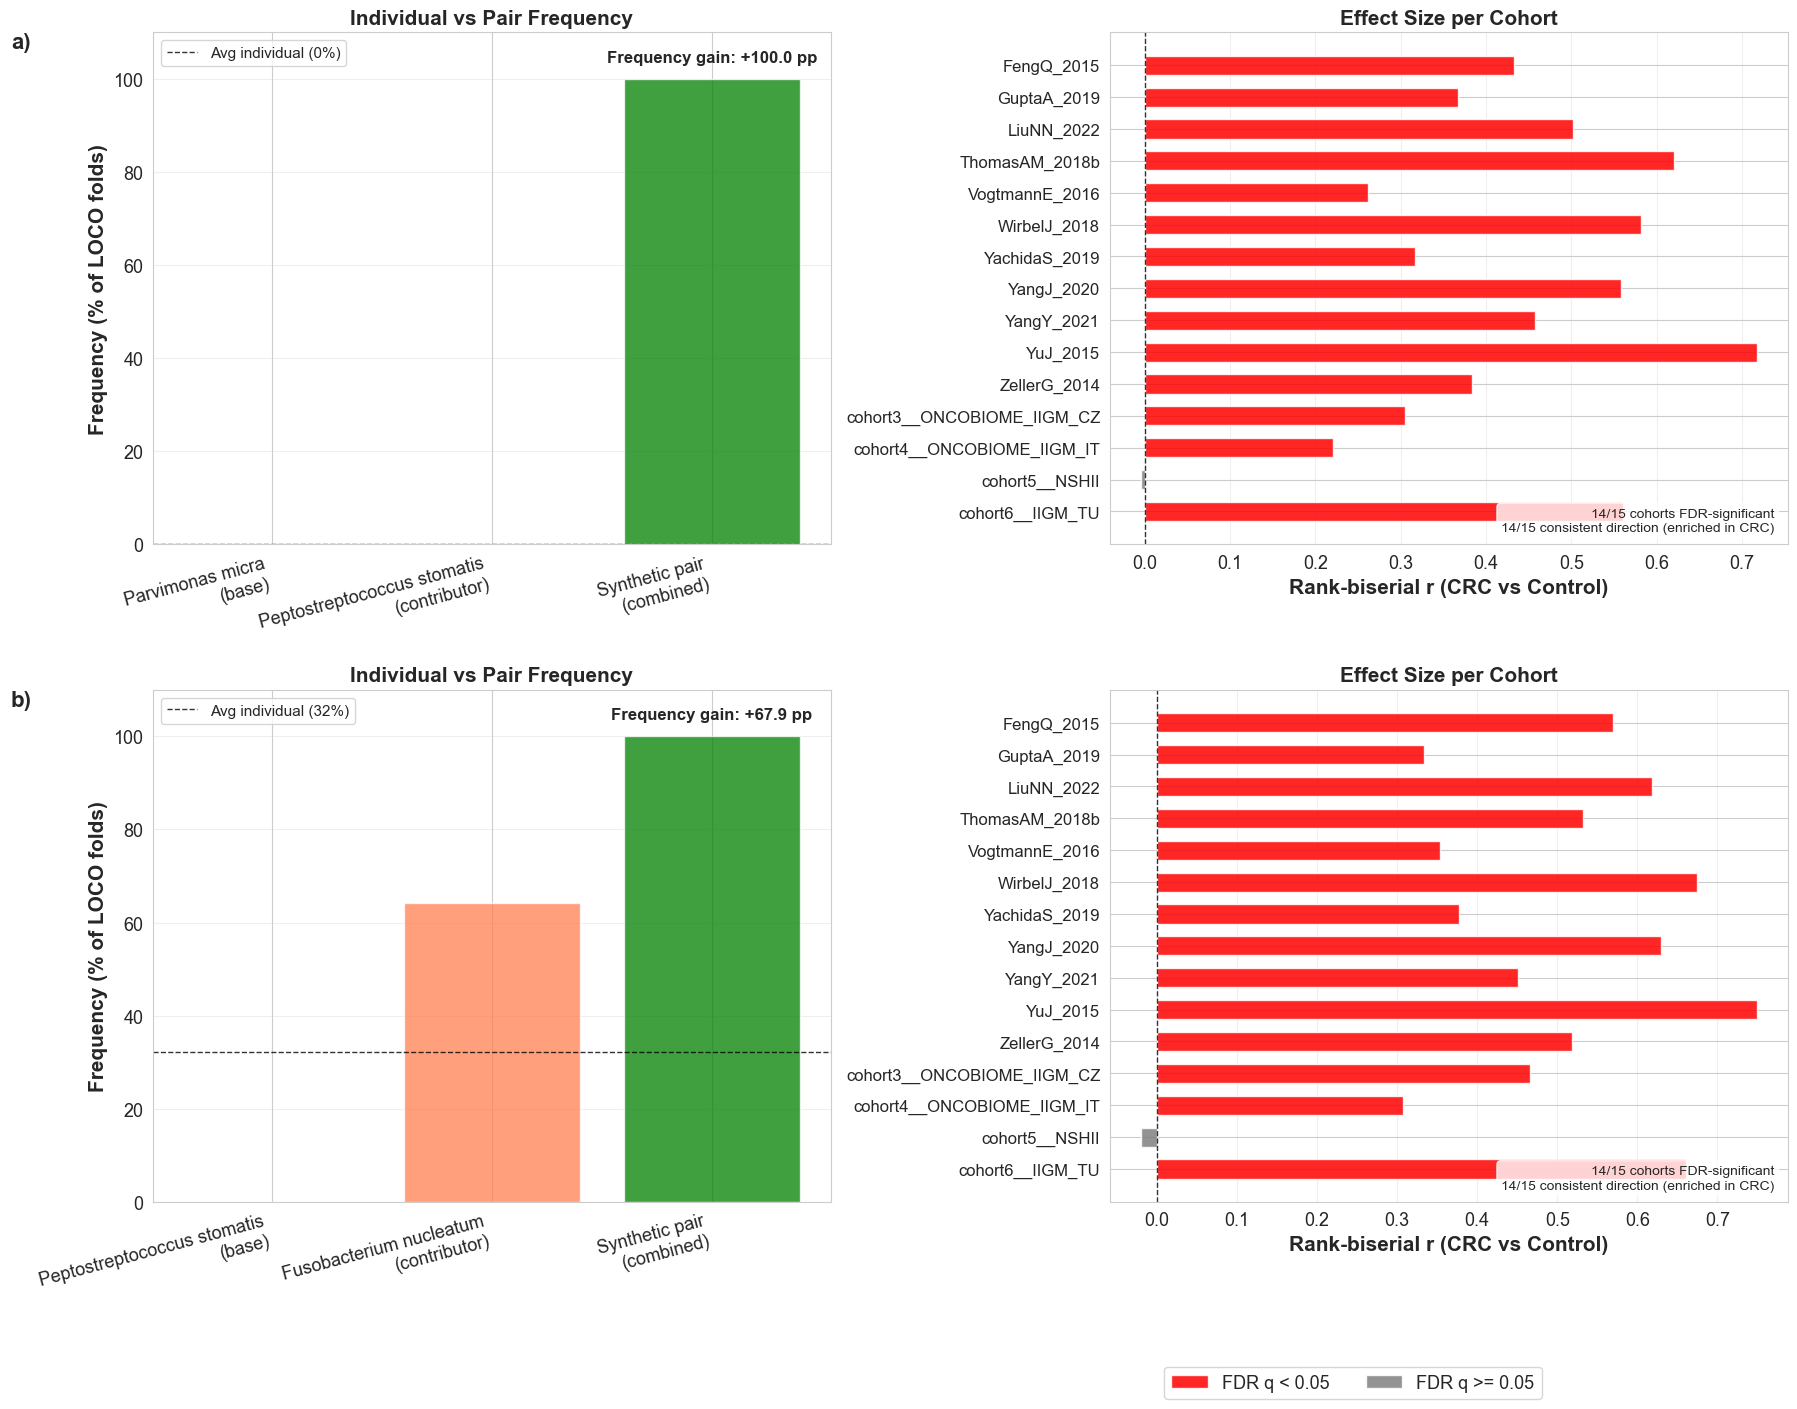

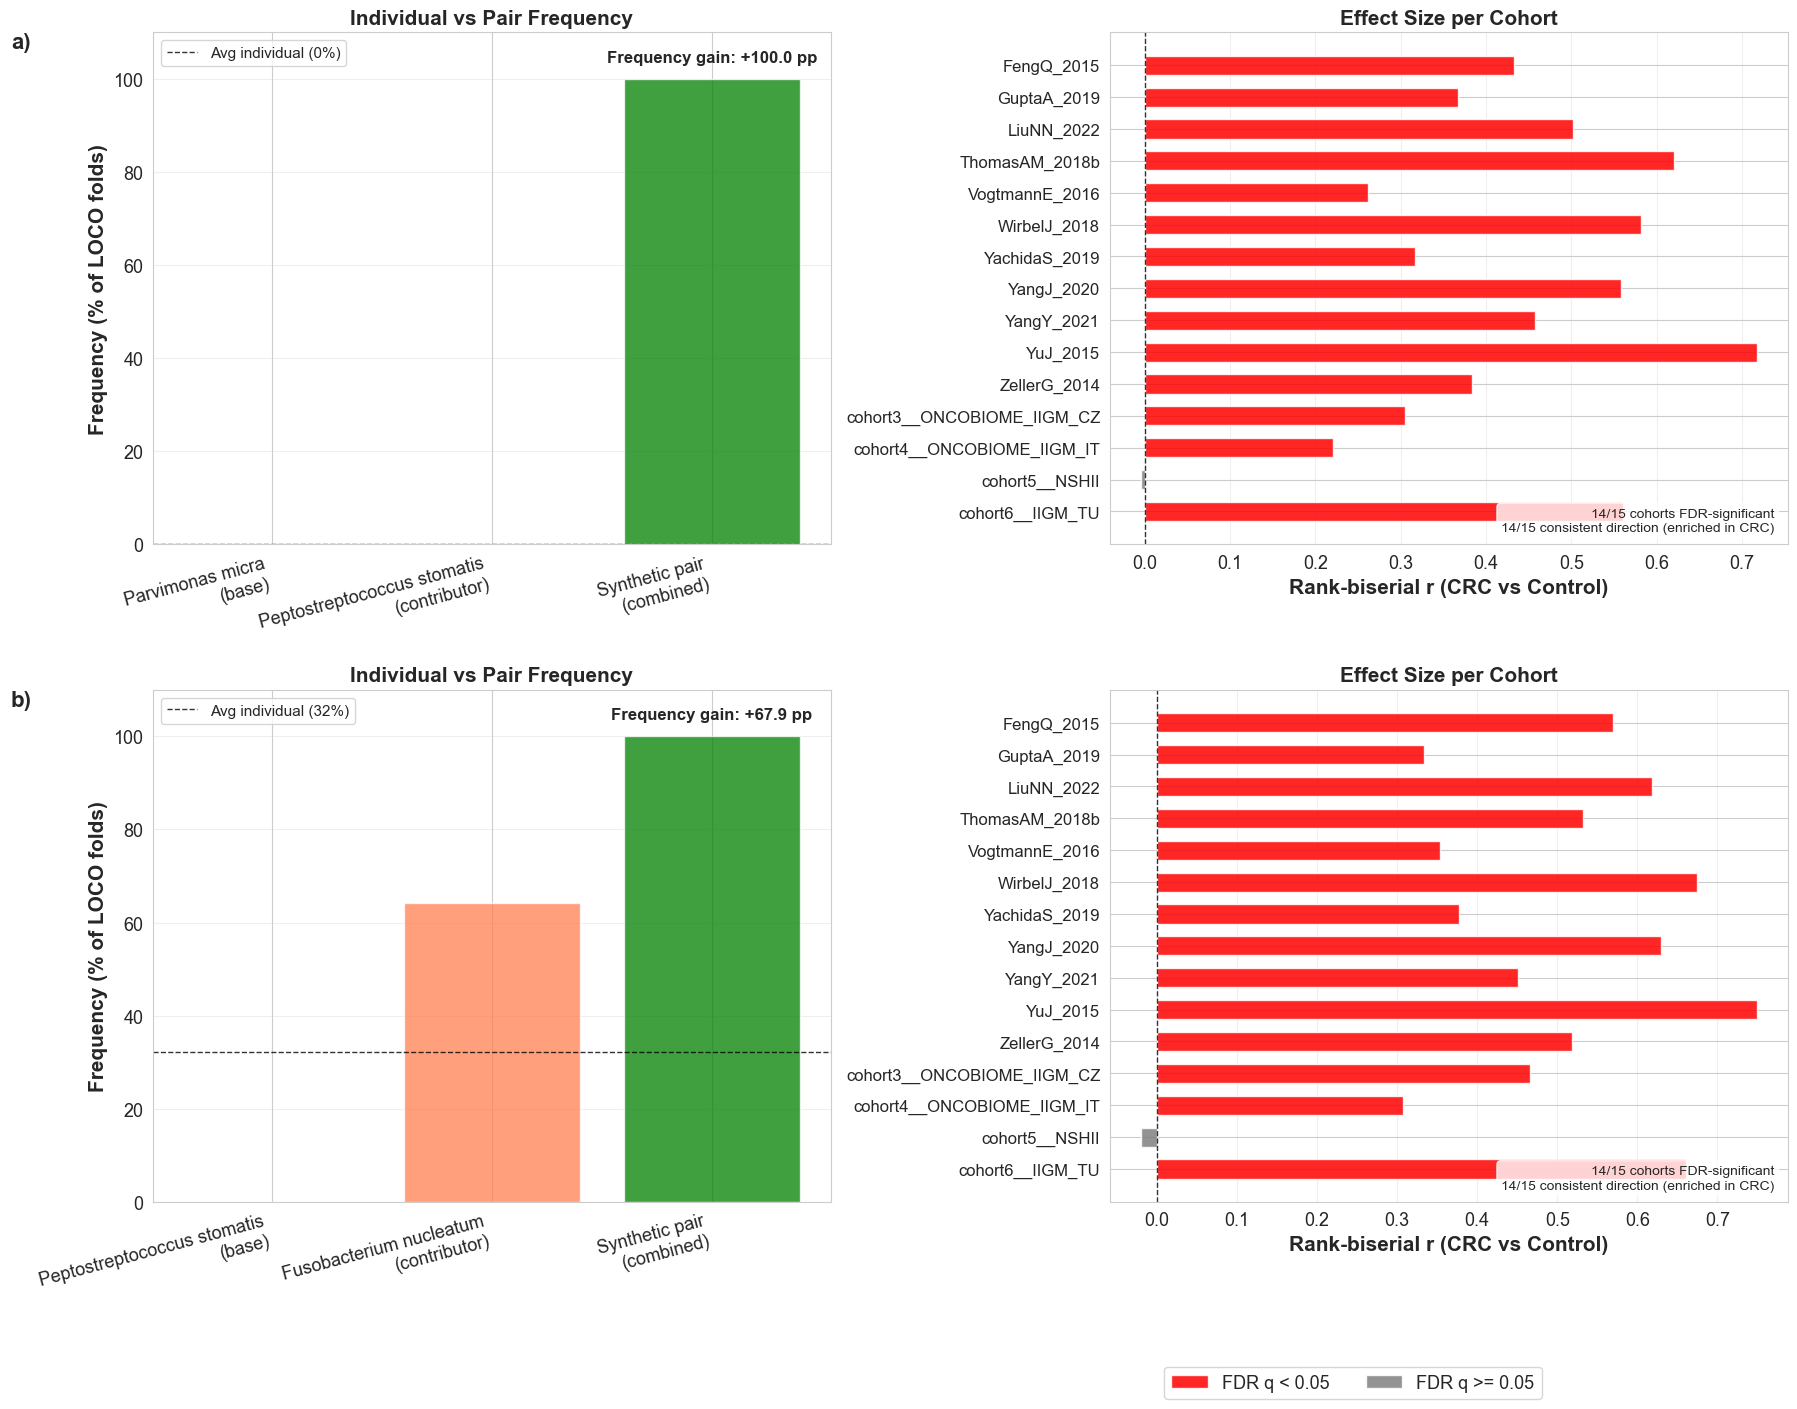

Figure saved: ../manuscript/Figure3.png

SUMMARY FOR RESULTS SECTION
Total stable pairs with prevalence gain: 235
Meta-significant across cohorts (FDR q < 0.05): 235/235
Pairs with consistent direction (>=14/15 cohorts): 225/235
Individual cohort tests significant (FDR q<0.05): 2751/3525 (78.0%)

Pairs involving Parvimonas micra: 48
Pairs involving Fusobacterium nucleatum: 125


In [8]:
# =============================================================================
# Figure 3: Representative pairs illustrating the hub pattern
# =============================================================================
# Selection strategy: pick pairs that best illustrate the two hub roles
# identified in consistent_mdfs_markers.ipynb:
#   (1) P. micra as BASE gaining IG — highest prevalence gain + strong meta effect
#   (2) F. nucleatum as CONTRIBUTOR providing IG — strongest meta effect
#
# Column a) Fold selection prevalence (bar chart): individual feature prevalences
#           vs synthetic pair prevalence, with dashed baseline at avg(F1, F2)
# Column b) Cohort-level effect size (horizontal bars): rank-biserial correlation
#           per cohort, colored by FDR significance (red = q<0.05, grey = n.s.)

import textwrap


def _pretty_name(x):
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return ''
    return str(x).replace('_', ' ')


def _wrap_label(x, width=28):
    s = _pretty_name(x)
    if not s:
        return ''
    wrapped = "\n".join(textwrap.wrap(s, width=width, break_long_words=False, replace_whitespace=False))
    return wrapped if wrapped else s


if len(results_df_best) == 0 or 'feature_pair' not in results_df_best.columns:
    print("Cannot create barplots - no results available")
else:
    # --- Merge prevalence gain + meta-significance for informed pair selection ---
    _meta = meta_best_df.copy() if len(meta_best_df) > 0 else pd.DataFrame()
    _sel = final_results_df[['Data Type', 'Feature', 'Selection % Gain']].rename(
        columns={'Data Type': 'data_type', 'Feature': 'feature_pair'}
    )
    if len(_meta) > 0:
        _ranked = _meta.merge(_sel, on=['data_type', 'feature_pair'], how='left')
    else:
        _ranked = results_df_best[['data_type', 'feature_pair']].drop_duplicates()

    # ---- Select strongest representatives ----
    # Representative 1: P. micra pair with highest prevalence gain AND strong effect
    #   → P. micra (0% indiv. prev) gaining IG from a contributing partner
    pmicra_pairs = _ranked[_ranked['feature_pair'].str.contains('Parvimonas_micra')]
    if len(pmicra_pairs) > 0 and 'Selection % Gain' in pmicra_pairs.columns:
        # Among P. micra pairs with +100 pp gain, pick strongest meta z
        top_gain = pmicra_pairs[pmicra_pairs['Selection % Gain'] >= 99.0]
        if len(top_gain) > 0 and 'z_meta' in top_gain.columns:
            rep1_row = top_gain.loc[top_gain['z_meta'].abs().idxmax()]
        else:
            rep1_row = pmicra_pairs.loc[pmicra_pairs['Selection % Gain'].idxmax()]
        rep1 = (rep1_row['data_type'], rep1_row['feature_pair'])
    else:
        rep1 = None

    # Representative 2: F. nucleatum as contributor — strongest overall meta z
    fnuc_pairs = _ranked[
        (_ranked['feature_pair'].str.contains('Fusobacterium_nucleatum')) &
        (_ranked['feature_pair'] != (rep1[1] if rep1 else ''))
    ]
    if len(fnuc_pairs) > 0 and 'z_meta' in fnuc_pairs.columns:
        rep2_row = fnuc_pairs.loc[fnuc_pairs['z_meta'].abs().idxmax()]
        rep2 = (rep2_row['data_type'], rep2_row['feature_pair'])
    else:
        rep2 = None

    selected_pairs = [p for p in [rep1, rep2] if p is not None]

    if len(selected_pairs) == 0:
        # Fallback: first 2 by meta z
        unique_pairs_df = results_df_best[['data_type', 'feature_pair']].drop_duplicates().head(2)
        selected_pairs = list(zip(unique_pairs_df['data_type'], unique_pairs_df['feature_pair']))

    n_pairs = len(selected_pairs)
    print(f"Selected representative pairs ({n_pairs}):")
    for dt, fp in selected_pairs:
        gain = _ranked.loc[(_ranked['data_type'] == dt) & (_ranked['feature_pair'] == fp), 'Selection % Gain']
        gain_val = f"+{gain.iloc[0]:.1f} pp" if len(gain) > 0 else "?"
        zmeta = _ranked.loc[(_ranked['data_type'] == dt) & (_ranked['feature_pair'] == fp), 'z_meta']
        z_val = f"z={zmeta.iloc[0]:.1f}" if len(zmeta) > 0 else "?"
        print(f"  - {dt} | {fp.replace('_', ' ')} | gain={gain_val} | {z_val}")

    # ---- Plot ----
    fig = plt.figure(figsize=(18, 6 * n_pairs + 2))

    for plot_idx, (data_type, feature_pair) in enumerate(selected_pairs):
        pair_data = results_df_best[
            (results_df_best['data_type'] == data_type) &
            (results_df_best['feature_pair'] == feature_pair)
        ].copy()
        pair_data = pair_data.sort_values('cohort')

        cohort_names = [c.replace('Public_study__', '').replace('This_study_', '') for c in pair_data['cohort']]
        y_pos = np.arange(len(cohort_names))

        # --- Column a): Fold selection prevalence ---
        ax1 = plt.subplot(n_pairs, 2, plot_idx * 2 + 1)

        sel_row = final_results_df[
            (final_results_df['Data Type'] == data_type) &
            (final_results_df['Feature'] == feature_pair)
        ]

        if len(sel_row) == 0:
            f1_sel, f2_sel, synth_sel = np.nan, np.nan, np.nan
            f1_name, f2_name = pair_data['feature1'].iloc[0], pair_data['feature2'].iloc[0]
        else:
            sel_row = sel_row.iloc[0]
            f1_sel = float(sel_row.get('Feature1_Selection%', np.nan))
            f2_sel = float(sel_row.get('Feature2_Selection%', np.nan))
            synth_sel = float(sel_row.get('Selection %', np.nan))
            f1_name = sel_row.get('Feature1', pair_data['feature1'].iloc[0])
            f2_name = sel_row.get('Feature2', pair_data['feature2'].iloc[0])

        # Identify base vs contributor for labeling
        if f1_sel <= f2_sel:
            base_name, contrib_name = f1_name, f2_name
            base_sel, contrib_sel = f1_sel, f2_sel
        else:
            base_name, contrib_name = f2_name, f1_name
            base_sel, contrib_sel = f2_sel, f1_sel

        labels = [
            _wrap_label(base_name, 30) + "\n(base)",
            _wrap_label(contrib_name, 30) + "\n(contributor)",
            f"Synthetic pair\n({data_type})",
        ]
        values = [base_sel, contrib_sel, synth_sel]
        colors = ['steelblue', 'coral', 'green']

        x_cat = np.arange(len(labels))
        ax1.bar(x_cat, values, color=colors, alpha=0.75)
        ax1.set_ylim(0, 110)
        ax1.set_ylabel('Frequency (% of LOCO folds)', fontsize=15, fontweight='bold')
        ax1.set_xticks(x_cat)
        ax1.set_xticklabels(labels, rotation=15, ha='right', fontsize=13)
        ax1.tick_params(axis='y', labelsize=13)
        ax1.grid(axis='y', alpha=0.3)

        avg_sel = np.nanmean([base_sel, contrib_sel])
        if not np.isnan(avg_sel):
            ax1.axhline(y=avg_sel, color='black', linestyle='--', linewidth=1.0, alpha=0.8,
                        label=f'Avg individual ({avg_sel:.0f}%)')
            if not np.isnan(synth_sel):
                gain = synth_sel - avg_sel
                ax1.text(2, min(105, synth_sel + 3), f"Frequency gain: {gain:+.1f} pp",
                         ha='center', va='bottom', fontsize=12, fontweight='bold')
            ax1.legend(fontsize=11, loc='upper left')

        ax1.set_title('Individual vs Pair Frequency', fontsize=15, fontweight='bold')

        # --- Column b): Effect size per cohort, colored by FDR ---
        ax2 = plt.subplot(n_pairs, 2, plot_idx * 2 + 2)
        r_vals = pair_data['rbc'].values

        if 'p_value_fdr' in pair_data.columns:
            q_vals = pair_data['p_value_fdr'].fillna(1.0)
            colors2 = ['red' if q < 0.05 else 'gray' for q in q_vals]
        else:
            colors2 = ['gray'] * len(pair_data)

        ax2.barh(y_pos, r_vals, height=0.6, color=colors2, alpha=0.85)
        ax2.axvline(x=0, color='black', linestyle='--', linewidth=1.0, alpha=0.8)

        ax2.set_yticks(y_pos)
        ax2.set_yticklabels(cohort_names, fontsize=12)
        ax2.tick_params(axis='x', labelsize=13)
        ax2.invert_yaxis()
        ax2.set_xlabel("Rank-biserial r (CRC vs Control)", fontsize=15, fontweight='bold')
        ax2.set_title("Effect Size per Cohort", fontsize=15, fontweight='bold')
        ax2.grid(axis='x', alpha=0.3)

        # Annotate with n significant / total cohorts
        n_sig = sum(1 for q in q_vals if q < 0.05) if 'p_value_fdr' in pair_data.columns else 0
        n_total = len(pair_data)
        n_consistent = sum(1 for r in r_vals if r > 0) if np.median(r_vals) > 0 else sum(1 for r in r_vals if r < 0)
        direction_label = "enriched in CRC" if np.median(r_vals) > 0 else "depleted in CRC"
        ax2.text(0.98, 0.02,
                 f"{n_sig}/{n_total} cohorts FDR-significant\n{n_consistent}/{n_total} consistent direction ({direction_label})",
                 transform=ax2.transAxes, ha='right', va='bottom', fontsize=10,
                 bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))

    # Panel labels (one per row, on left subplot of each row)
    row_panel_labels = ['a)', 'b)', 'c)', 'd)']
    for row_idx in range(n_pairs):
        ax_left = fig.axes[row_idx * 2]
        ax_left.text(
            -0.18, 1.0, row_panel_labels[row_idx],
            transform=ax_left.transAxes, fontsize=16, fontweight='bold', va='top', ha='right',
        )

    # Legend for bar colors
    from matplotlib.patches import Patch
    legend_elements = [Patch(facecolor='red', alpha=0.85, label='FDR q < 0.05'),
                       Patch(facecolor='gray', alpha=0.85, label='FDR q >= 0.05')]
    fig.legend(handles=legend_elements, loc='lower center', ncol=2, frameon=True,
               fontsize=13, bbox_to_anchor=(0.75, -0.02))

    plt.tight_layout(rect=[0, 0.04, 1, 0.99])
    _fig_path = '../manuscript/Figure3.png'
    fig.savefig(_fig_path, dpi=300, bbox_inches='tight')
    fig.savefig(_fig_path.replace('.png', '.pdf'), bbox_inches='tight')
    display(fig)
    plt.show()
    print(f"Figure saved: {_fig_path}")

    # --- Summary statistics for paragraph ---
    print("\n" + "="*80)
    print("SUMMARY FOR RESULTS SECTION")
    print("="*80)
    n_total_pairs = len(final_results_df)
    n_meta_sig = (meta_best_df['q_meta_fdr'] < 0.05).sum() if len(meta_best_df) > 0 else 0
    print(f"Total stable pairs with prevalence gain: {n_total_pairs}")
    print(f"Meta-significant across cohorts (FDR q < 0.05): {n_meta_sig}/{n_total_pairs}")

    # Direction consistency
    if len(meta_best_df) > 0:
        n_consistent = meta_best_df['direction'].apply(
            lambda d: max(int(d.split('/')[0].replace('+','')), int(d.split('/')[1].replace('-','')))
        )
        n_highly_consistent = (n_consistent >= 14).sum()
        print(f"Pairs with consistent direction (>=14/15 cohorts): {n_highly_consistent}/{n_total_pairs}")

    # Per-cohort FDR significance
    if 'p_value_fdr' in results_df_best.columns:
        total_tests = len(results_df_best)
        total_sig = (results_df_best['p_value_fdr'] < 0.05).sum()
        print(f"Individual cohort tests significant (FDR q<0.05): {total_sig}/{total_tests} ({100*total_sig/total_tests:.1f}%)")

    # Hub-specific counts
    pm_pairs = len(final_results_df[final_results_df['Feature'].str.contains('Parvimonas_micra')])
    fn_pairs = len(final_results_df[final_results_df['Feature'].str.contains('Fusobacterium_nucleatum')])
    print(f"\nPairs involving Parvimonas micra: {pm_pairs}")
    print(f"Pairs involving Fusobacterium nucleatum: {fn_pairs}")
    print("="*80)